# Astronomical Camera Calibration Analysis (Bias & Dark Frames)

This notebook presents an analysis of raw calibration frames (**Bias** and **Dark**) captured with the **ZWO ASI183MM Pro** camera. The goal is to evaluate sensor read noise stability and investigate how exposure time and sensor cooling affect thermal dark current and hot pixel generation.



Importing custom calibration functions from `functions.py` and `matplotlib` for data visualization.


In [1]:
from functions import *
import matplotlib.pyplot as plt

Generating and saving **Master Bias** frames for **-0.5 °C** and **15 °C** using paths from `paths.txt`.


In [2]:
#Bias for -1 C
bias1_path = get_path(1)
bias1, header_bias1 = create_data_stack(bias1_path, "bias_*.fit*")
bias1_master = create_master(bias1)
save_master(bias1_path, "master_bias.fits", bias1_master, header_bias1)

#Bias for 15 C
bias15_path = get_path(5)
bias15, header_bias15 = create_data_stack(bias15_path, "bias_*.fit*")
bias15_master = create_master(bias15)
save_master(bias15_path, "master_bias.fits", bias15_master, header_bias15)

Generating and saving **Master Dark** frames across different exposure times at **15 °C** and **-0.5 °C**.


In [3]:
#Dark for 15 C 1 s
dark151_path=get_path(2)
dark151, header_dark151=create_data_stack(dark151_path, "dark_*.fit*")
dark151_master=create_master(dark151)
save_master(dark151_path, "master_dark.fits", dark151_master, header_dark151)

#Dark for 15 C 60 s
dark1560_path=get_path(3)
dark1560, header_dark1560=create_data_stack(dark1560_path, "dark_*.fit*")
dark1560_master=create_master(dark1560)
save_master(dark1560_path, "master_dark.fits", dark1560_master, header_dark1560)

#Dak for 15 C 10 s
dark1510_path=get_path(6)
dark1510, header_dark1510=create_data_stack(dark1510_path, "dark_*.fit*")
dark1510_master=create_master(dark1510)
save_master(dark1510_path, "master_dark.fit", dark1510_master, header_dark1510)

In [4]:
#Dark for -0.5 C 10 s
dark0510_path=get_path(7)
dark0510, header_dark0510=create_data_stack(dark0510_path, "dark_*.fit*")
dark0510_master=create_master(dark0510)
save_master(dark0510_path, "master_dark.fit", dark0510_master, header_dark0510)

#Dark for -0.5 C 1 s
dark051_path=get_path(4)
dark051, header_dark051=create_data_stack(dark051_path, "dark_*.fit*")
dark051_master=create_master(dark051)
save_master(dark051_path, "master_dark.fits", dark051_master, header_dark051)

---
### Bias Frames Comparison
Plotting histograms for both **Master Bias** frames across different temperatures (**15 °C** and **-0.5 °C**).

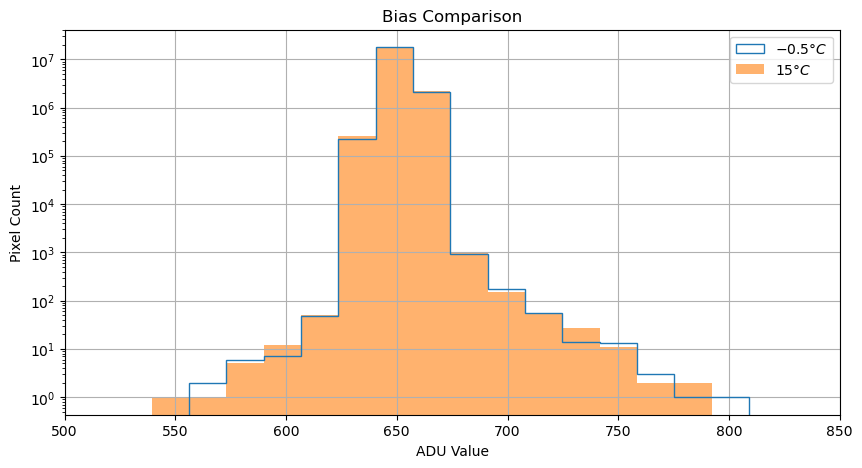

In [45]:
#Histograms for Biases
plt.figure(figsize=(10, 5))
bins = np.linspace(0, 1500, 90)
plt.hist(bias1_master.ravel(), histtype="step", bins=bins, alpha=1, label="$-0.5 \degree C$")
plt.hist(bias15_master.ravel(), bins=bins, alpha=0.6, label="$15 \degree C$")
plt.xlim(500, 850)
plt.yscale('log')
plt.title("Bias Comparison")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()

plt.show()

Both Master Bias distributions are nearly identical, confirming that read noise does not depend on temperature. Slight differences are just normal statistical variations resulting from a finite number of combined frames.


---
### Dark Frames Comparison
#### Exposure Time Comparison (Fixed Temperatures)
Plotting histograms for **Master Dark** to compare different exposure times at **15 °C** (1 s, 10 s, 60 s) and **-0.5 °C** (1 s, 10 s).


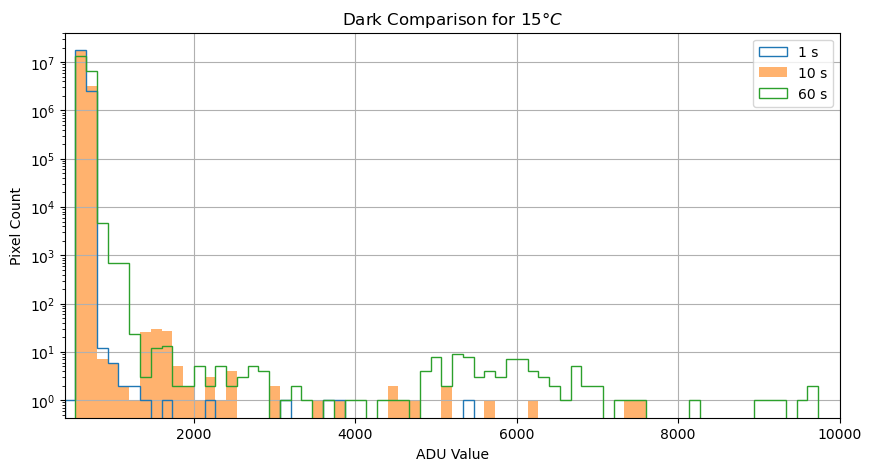

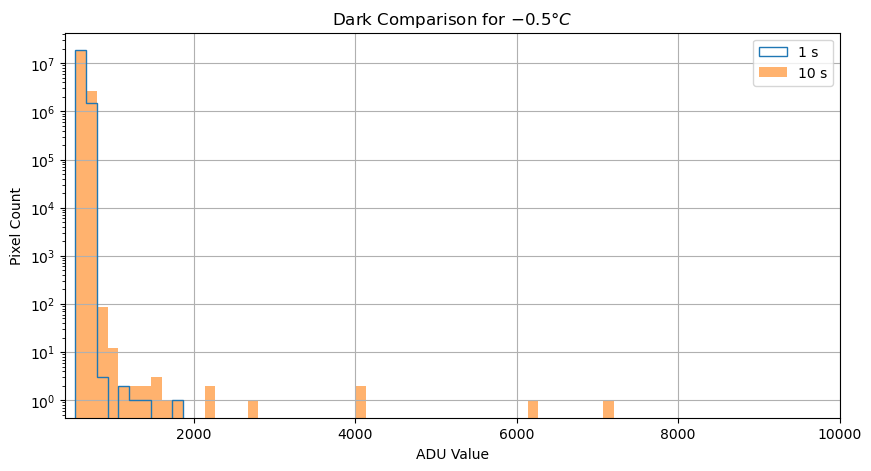

In [47]:
#Histogram for 15 C
plt.figure(figsize=(10, 5))
bins = np.linspace(0, 10000, 76)
plt.hist(dark151_master.ravel(),histtype="step", bins=bins, alpha=1, label="1 s")
plt.hist(dark1510_master.ravel(), bins=bins, alpha=0.6, label="10 s")
plt.hist(dark1560_master.ravel(), bins=bins,histtype="step", alpha=1, label="60 s")
plt.xlim(400,10000)
plt.yscale('log')
plt.title("Dark Comparison for $15 \degree C$")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()
plt.show()

#Histogram for -0.5 C
plt.figure(figsize=(10, 5))
plt.hist(dark051_master.ravel(),histtype="step", bins=bins, alpha=1 , label="1 s")
plt.hist(dark0510_master.ravel(),bins=bins, alpha=0.6 , label="10 s")
plt.xlim(400, 10000)
plt.yscale('log')
plt.title("Dark Comparison for $-0.5 \degree C$")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()
plt.show()


All distributions share the same baseline bias peak, while at 15 °C the 10 s exposure slightly broadens the peak to the right and the 60 s exposure shows a low secondary distribution around 6000 ADU. At -0.5 °C both 1 s and 10 s distributions overlap tightly around the main peak, though the 10 s frame still exhibits slightly more isolated high-value hot pixels, confirming that thermal noise still accumulates slowly with exposure time even when cooled.


#### Temperature Comparison (Fixed Exposure Times)
Plotting histograms to compare sensor temperatures (**-0.5 °C** and **15 °C**) for fixed exposure times of **1 s** and **10 s**.


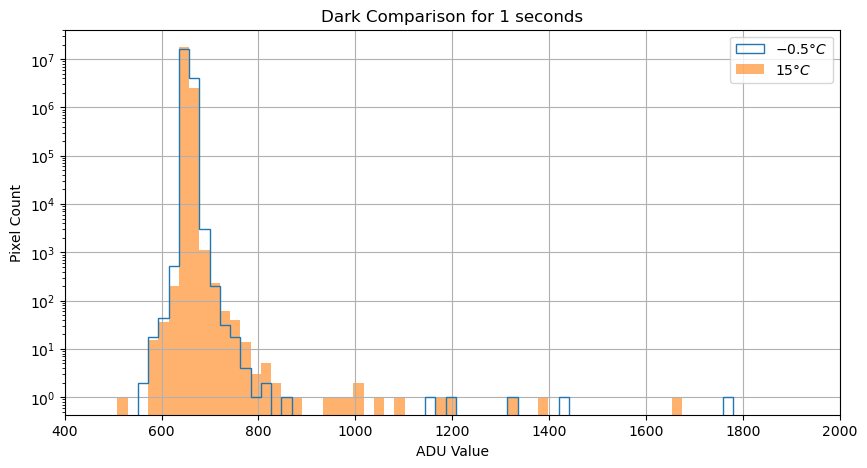

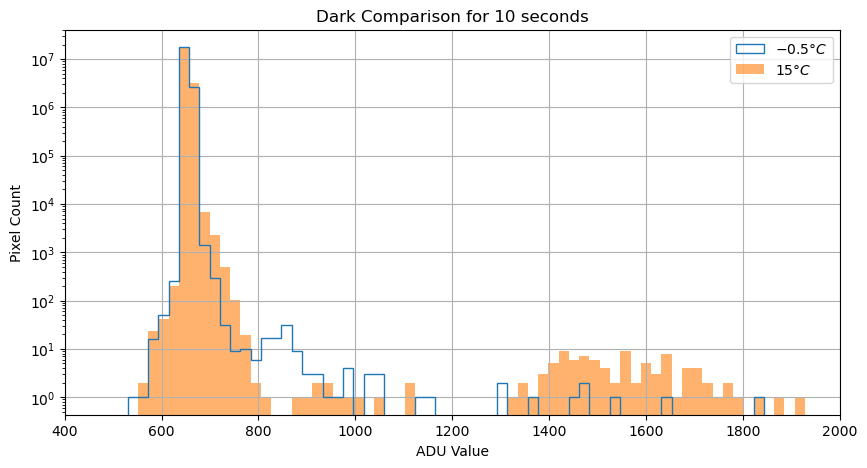

In [46]:
bins = np.linspace(0, 3200, 152)

#Histograms for Dark 1 s
plt.figure(figsize=(10, 5))
plt.hist(dark051_master.ravel(), histtype="step", bins=bins, alpha=1, label="$-0.5 \degree C$")
plt.hist(dark151_master.ravel(), bins=bins, alpha=0.6, label="$15 \degree C$")
plt.xlim(400, 2000)
plt.yscale('log')
plt.title("Dark Comparison for 1 seconds")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()
plt.show()

#Histograms for Dark 10 s
plt.figure(figsize=(10, 5))
plt.hist(dark0510_master.ravel(), histtype="step", bins=bins, alpha=1, label="$-0.5 \degree C$")
plt.hist(dark1510_master.ravel(), bins=bins, alpha=0.6, label="$15 \degree C$")
plt.xlim(400, 2000)
plt.yscale('log')
plt.title("Dark Comparison for 10 seconds")
plt.xlabel("ADU Value")
plt.ylabel("Pixel Count")
plt.grid(True)
plt.legend()
plt.show()



Both comparisons retain the main baseline bias peak, with the 15 °C frames consistently showing more hot pixels than at -0.5 °C. At 10 s, the 15 °C distribution develops a subtle secondary bump centered around 1500 ADU, while at -0.5 °C a similar slight broadening appears right next to the main peak, showing how cooling shifts this warm-pixel population closer to the baseline level.


---
### Summary & Conclusions
* **Bias Stability:** The baseline bias signal is present across all calibration frames and remains independent of both sensor temperature and exposure time.
* **Thermal & Time Dependence:** Dark current and hot pixels increase with both higher sensor temperature and longer exposure times, shifting warm-pixel distributions toward higher ADU values.
* **Key Takeaways:** Cooling the sensor and reducing the exposure time drastically suppresses thermal noise.
